# C0 · predicted heatmap vs error anisotropy under round targets (free analysis 4 of 4)

**Why.** STAR (Zhou et al. 2023) found that heatmaps trained with round targets are already oval along facial contours, and
Thaler et al. (2021) found that learned anisotropic targets line up with the localisation error. Arm T of the plan was to check
the second point by running Thaler's method. Most of the question can be answered without new runs: the `gaussfit` decoder already
stores a Gaussian fit to every predicted heatmap (`fit_sxx`, `fit_sxy`, `fit_syy`, canvas px²). This notebook asks, on the round
baseline runs at each tier's σ₀:

1. **Are round-target heatmaps anisotropic?** (STAR on medical data.) The fitted heatmap covariance contains the round target
   itself, σ₀² I, so the anisotropy is read from the excess, C_heatmap − σ₀² I.
2. **Is the heatmap's long axis the error's long axis?** Angle between the mean heatmap covariance's major axis and the error
   covariance's major axis, on landmarks whose error SD ratio is ≥ 1.3 (the plan's P0b/P0d threshold). Subtracting σ₀² I does not
   change the eigenvectors, so this angle is the same for the raw and the excess covariance and is defined even where the excess
   is not positive definite (the heatmap narrower than the target along its minor axis). The SD ratio of the excess needs a
   positive-definite excess; the eigenvalue difference (major − minor, mm²) does not, and is compared with the error's.
3. **Does the heatmap's spread track the error image by image?** Spearman correlation, per landmark, between the trace of the
   per-image excess covariance and the squared error.

Errors: primary decoder (quadratic), final checkpoints, gross failures (> 4 mm) removed, each run centred on its own mean, as for
the baseline axes. Status: exploratory and descriptive.

In [1]:
ANALYSIS = "heatmap_anisotropy"
import os, json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def _repo_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
W_ROOT = Path(os.environ.get("C0_WEIGHTS", "/tf/weights/C0" if os.path.isdir("/tf/weights/C0") else str(_REPO / "weights" / "C0")))
OUT = W_ROOT / "analyses" / ANALYSIS
OUT.mkdir(parents=True, exist_ok=True)
PD = "quadratic"
MM_PER_PX = 0.3125
GROSS_MM = 4.0
RATIO_MIN = 1.3
TIERS = {"High": {"net": "UNet-64", "sigma0_px": 5.0, "runs": [f"C0_ISBI2015_High_R_w1.00_s{s}" for s in (1, 2, 3, 101, 102)]},
         "Medium": {"net": "UNet-32", "sigma0_px": 5.0 * 2 ** 0.5, "runs": [f"C0_ISBI2015_Medium_R_w1.41_s{s}" for s in (1, 2, 3)]}}
COLORS = {"High": "#0072B2", "Medium": "#D55E00"}
NAMES = pd.read_csv(W_ROOT / "ISBI2015_High" / "arm_A_summary" / "alpha_by_landmark.csv").set_index("landmark").name

def load_run(t, rid):
    d = W_ROOT / f"ISBI2015_{t}" / rid
    assert (d / "DONE").exists(), f"{rid}: not finished"
    p = pd.read_csv(d / "predictions_test.csv.gz")
    p = p[p.checkpoint == "final"]
    q = p[p.decoder == PD][["image_id", "landmark", "dx_mm", "dy_mm", "r_mm"]]
    g = p[p.decoder == "gaussfit"][["image_id", "landmark", "fit_sxx", "fit_sxy", "fit_syy"]]
    return q.merge(g, on=["image_id", "landmark"]).assign(run_id=rid)

DATA = {t: pd.concat([load_run(t, r) for r in v["runs"]], ignore_index=True) for t, v in TIERS.items()}
print({t: (len(d), d.run_id.nunique()) for t, d in DATA.items()})

{'High': (23750, 5), 'Medium': (14250, 3)}


## 1. Per-landmark error and heatmap covariances

In [2]:
def axes_of(C):
    ev, V = np.linalg.eigh(C)
    ang = (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90
    ratio = math.sqrt(ev[1] / ev[0]) if ev[0] > 0 else np.nan
    return ang, ratio, ev

def angdiff(a, b):
    return abs((a - b + 90) % 180 - 90)

rows, per_image = [], []
for t, d in DATA.items():
    s0mm2 = (TIERS[t]["sigma0_px"] * MM_PER_PX) ** 2
    d = d[(d.r_mm <= GROSS_MM) & np.isfinite(d.fit_sxx) & np.isfinite(d.fit_syy) & np.isfinite(d.fit_sxy)].copy()
    d[["hxx", "hxy", "hyy"]] = d[["fit_sxx", "fit_sxy", "fit_syy"]].values * MM_PER_PX ** 2
    for lm, g in d.groupby("landmark"):
        e = np.concatenate([np.stack([h.dx_mm - h.dx_mm.mean(), h.dy_mm - h.dy_mm.mean()], 1) for _, h in g.groupby("run_id")])
        Ce = np.cov(e.T)
        Ch = np.array([[g.hxx.mean(), g.hxy.mean()], [g.hxy.mean(), g.hyy.mean()]])
        Cx = Ch - s0mm2 * np.eye(2)
        ae, re_, eve = axes_of(Ce)
        ah, rh, evh = axes_of(Ch)
        ax_, rx, evx = axes_of(Cx)
        tr_ex = (g.hxx + g.hyy) - 2 * s0mm2
        rho, p_rho = stats.spearmanr(tr_ex, g.r_mm ** 2)
        rows.append({"tier": t, "landmark": lm, "name": NAMES[lm], "n": len(g),
                     "err_eig_diff_mm2": eve[1] - eve[0], "hm_eig_diff_mm2": evh[1] - evh[0],
                     "err_sd_major_mm": math.sqrt(eve[1]), "err_sd_minor_mm": math.sqrt(max(eve[0], 0)), "err_ratio": re_, "err_angle": ae,
                     "hm_sd_major_mm": math.sqrt(evh[1]), "hm_sd_minor_mm": math.sqrt(evh[0]), "hm_ratio": rh, "hm_angle": ah,
                     "excess_eig_major_mm2": evx[1], "excess_eig_minor_mm2": evx[0], "excess_positive_definite": bool(evx[0] > 0),
                     "excess_ratio": rx, "excess_angle": ax_,
                     "angle_err_vs_excess": angdiff(ae, ax_), "angle_err_vs_heatmap": angdiff(ae, ah),
                     "excess_sd_major_mm": math.sqrt(max(evx[1], 0)), "spearman_trace_excess_vs_sq_error": rho, "spearman_p": p_rho})
LMT = pd.DataFrame(rows)
LMT.round(4).to_csv(OUT / "heatmap_vs_error_by_landmark.csv", index=False)
LMT.pivot_table(index="name", columns="tier", values=["err_ratio", "excess_ratio", "angle_err_vs_excess", "spearman_trace_excess_vs_sq_error"]).round(2)

angle_err_vs_excess  ... spearman_trace_excess_vs_sq_error
tier                                  High  ...                            Medium
name                                        ...                                  
anterior nasal spine                  0.26  ...                              0.13
articulare                           19.10  ...                              0.23
gnathion                             24.78  ...                             -0.01
gonion                                3.40  ...                             -0.02
lower incisal incision               42.01  ...                              0.27
lower lip                            26.62  ...                              0.06
menton                                8.14  ...                              0.14
nasion                               20.35  ...                              0.10
orbitale                              7.97  ...                             -0.07
pogonion                             34.95  ...                              0.05
porion                               10.87  ...                              0.10
posterior nasal spine                 2.87  ...                             -0.06
sella                                27.82  ...                             -0.09
soft-tissue pogonion                 13.22  ...                              0.03
subnasale                            19.61  ...                              0.06
subspinale (A)                        5.84  ...                              0.12
supramentale (B)                     17.89  ...                              0.06
upper incisal incision               15.19  ...                              0.20
upper lip                             5.17  ...                              0.13

[19 rows x 8 columns]

## 2. Summary

* **Anisotropy (STAR):** median heatmap SD ratio (raw and excess) and the share of landmarks with excess ratio ≥ 1.15.
* **Alignment:** median angle between excess and error major axes, landmarks with error SD ratio ≥ 1.3; the share within 20°
  (the plan's P0d tolerance). Under random orientation the median would be 45°.
* **Ratio agreement:** Spearman correlation across landmarks between error SD ratio and excess SD ratio.
* **Per-image tracking:** median over landmarks of the per-image Spearman ρ, and how many landmarks have ρ > 0 at p < 0.05.
* **Magnitude:** the excess heatmap SD along its major axis compared with the error SD along the error major axis.

In [3]:
summ = {}
for t in TIERS:
    g = LMT[LMT.tier == t]
    al = g[g.err_ratio >= RATIO_MIN]
    summ[t] = {"landmarks": len(g), "median_heatmap_ratio_raw": g.hm_ratio.median(),
               "median_excess_ratio": g[g.excess_positive_definite].excess_ratio.median(),
               "share_excess_ratio_ge_1.15": float((g[g.excess_positive_definite].excess_ratio >= 1.15).mean()),
               "landmarks_excess_not_positive_definite": int((~g.excess_positive_definite).sum()),
               "alignment_landmarks": len(al), "median_angle_err_vs_excess_deg": al.angle_err_vs_excess.median(),
               "share_within_20deg": float((al.angle_err_vs_excess < 20).mean()) if len(al) else np.nan,
               "spearman_err_ratio_vs_excess_ratio": stats.spearmanr(g.err_ratio, g.excess_ratio, nan_policy="omit")[0],
               "spearman_err_eigdiff_vs_hm_eigdiff": stats.spearmanr(g.err_eig_diff_mm2, g.hm_eig_diff_mm2)[0],
               "median_hm_eigdiff_over_err_eigdiff": float((g.hm_eig_diff_mm2 / g.err_eig_diff_mm2).median()),
               "median_per_image_spearman": g.spearman_trace_excess_vs_sq_error.median(),
               "landmarks_per_image_rho_pos_sig": int(((g.spearman_trace_excess_vs_sq_error > 0) & (g.spearman_p < 0.05)).sum()),
               "median_excess_sd_over_error_sd": float((g.excess_sd_major_mm / g.err_sd_major_mm).median())}
SUMM = pd.DataFrame(summ)
(OUT / "heatmap_vs_error_summary.json").write_text(json.dumps(summ, indent=1, default=float))
SUMM.round(3)

,High,Medium
landmarks,19.000,19.000
median_heatmap_ratio_raw,1.011,1.007
median_excess_ratio,1.876,2.419
share_excess_ratio_ge_1.15,1.000,1.000
landmarks_excess_not_positive_definite,4.000,13.000
alignment_landmarks,16.000,15.000
median_angle_err_vs_excess_deg,16.538,10.878
share_within_20deg,0.688,0.733
spearman_err_ratio_vs_excess_ratio,0.175,0.257
spearman_err_eigdiff_vs_hm_eigdiff,0.198,0.270


## 3. Figure

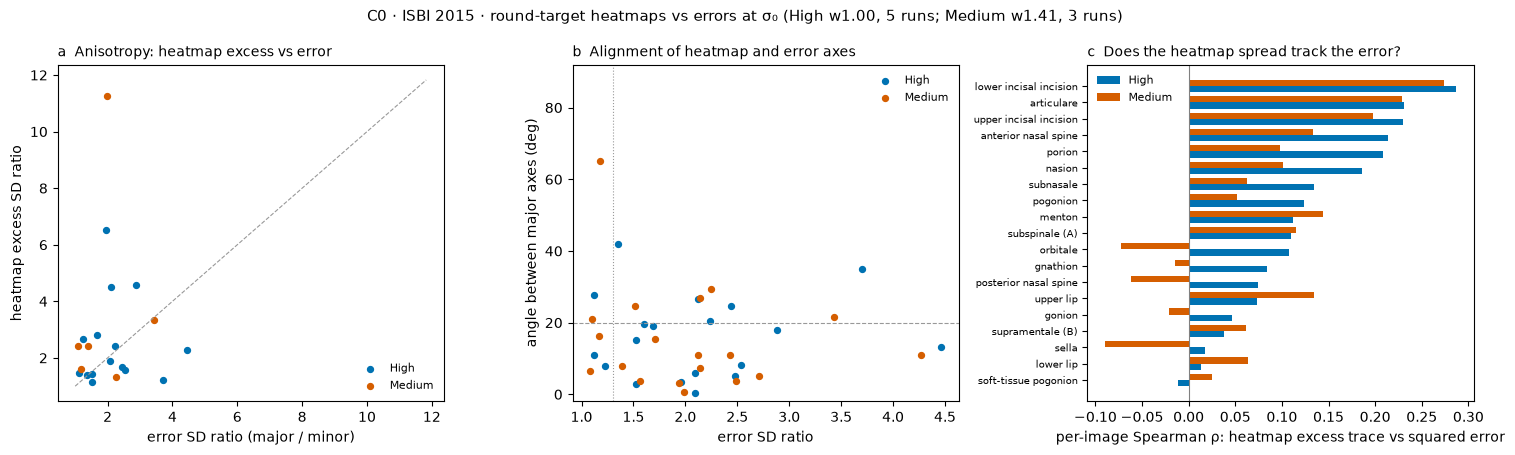

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axs[0]
for t in TIERS:
    g = LMT[(LMT.tier == t) & LMT.excess_positive_definite]
    ax.scatter(g.err_ratio, g.excess_ratio, s=18, color=COLORS[t], label=t)
lim = [1, max(LMT.err_ratio.max(), LMT.excess_ratio.max(skipna=True)) * 1.05]
ax.plot(lim, lim, color="0.6", ls="--", lw=0.8)
ax.set_xlabel("error SD ratio (major / minor)"); ax.set_ylabel("heatmap excess SD ratio")
ax.set_title("a  Anisotropy: heatmap excess vs error", loc="left", fontsize=10); ax.legend(fontsize=8, frameon=False)
ax = axs[1]
for t in TIERS:
    g = LMT[LMT.tier == t]
    ax.scatter(g.err_ratio, g.angle_err_vs_excess, s=18, color=COLORS[t], label=t)
ax.axvline(RATIO_MIN, color="0.6", ls=":", lw=0.8); ax.axhline(20, color="0.6", ls="--", lw=0.8)
ax.set_ylim(-2, 92)
ax.set_xlabel("error SD ratio"); ax.set_ylabel("angle between major axes (deg)")
ax.set_title("b  Alignment of heatmap and error axes", loc="left", fontsize=10); ax.legend(fontsize=8, frameon=False)
ax = axs[2]
order = LMT[LMT.tier == "High"].sort_values("spearman_trace_excess_vs_sq_error").landmark.tolist()
for k, t in enumerate(TIERS):
    g = LMT[LMT.tier == t].set_index("landmark").reindex(order)
    ax.barh(np.arange(len(order)) + (k - 0.5) * 0.38, g.spearman_trace_excess_vs_sq_error, height=0.38, color=COLORS[t], label=t)
ax.set_yticks(range(len(order))); ax.set_yticklabels([NAMES[l] for l in order], fontsize=7)
ax.axvline(0, color="0.5", lw=0.8)
ax.set_xlabel("per-image Spearman ρ: heatmap excess trace vs squared error")
ax.set_title("c  Does the heatmap spread track the error?", loc="left", fontsize=10); ax.legend(fontsize=8, frameon=False)
fig.suptitle("C0 · ISBI 2015 · round-target heatmaps vs errors at σ₀ (High w1.00, 5 runs; Medium w1.41, 3 runs)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "heatmap_anisotropy.png", dpi=150)